İP 6 Başladı: Sonuçların Görselleştirilmesi...


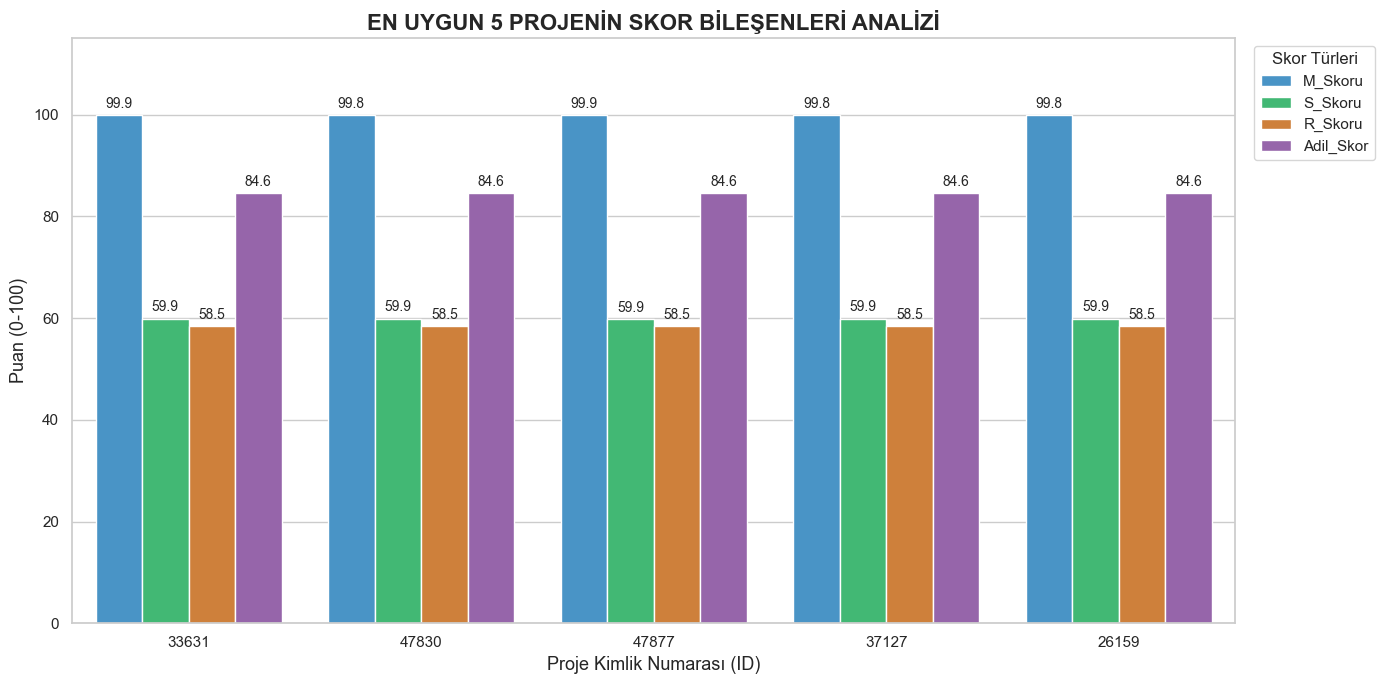


✅ Başarılı! Grafik 'IP6_Sonuc_Grafigi.png' olarak kaydedildi.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("İP 6 Başladı: Sonuçların Görselleştirilmesi...")

# 1. Veriyi Yükle
try:
    df = pd.read_csv("IP5_Nihai_Adil_Siralama.csv")
    df_top5 = df.head(5).copy()
    
    # --- DÜZELTME: R_Skoru sütununu ekle ---
    # İP 4'ten gelen değeri buraya sabit olarak giriyoruz (Sizin skorunuz 58.49 idi)
    df_top5['R_Skoru'] = 58.49
    
    # İsimleri kısalt (Linkten ID çek)
    df_top5['Kisa_Isim'] = df_top5['link'].apply(lambda x: x.split('/')[-1].replace('_en', '').upper())
    
except FileNotFoundError:
    print("HATA: CSV dosyası bulunamadı.")
    raise

# 2. Grafik Ayarları
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 7))

# Sütunları erit (melt) - R_Skoru artık mevcut
df_melted = df_top5.melt(id_vars=['Kisa_Isim'], 
                         value_vars=['M_Skoru', 'S_Skoru', 'R_Skoru', 'Adil_Skor'],
                         var_name='Skor_Turu', 
                         value_name='Puan')

# 3. Çubuk Grafiği
palette = {"M_Skoru": "#3498db", "S_Skoru": "#2ecc71", "R_Skoru": "#e67e22", "Adil_Skor": "#9b59b6"}
ax = sns.barplot(x='Kisa_Isim', y='Puan', hue='Skor_Turu', data=df_melted, palette=palette)

# 4. Süslemeler
plt.title('EN UYGUN 5 PROJENİN SKOR BİLEŞENLERİ ANALİZİ', fontsize=16, fontweight='bold')
plt.ylabel('Puan (0-100)', fontsize=13)
plt.xlabel('Proje Kimlik Numarası (ID)', fontsize=13)
plt.ylim(0, 115)
plt.legend(title='Skor Türleri', bbox_to_anchor=(1.01, 1), loc='upper left')

# Değerleri yazdır
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3, fontsize=10)

plt.tight_layout()
plt.savefig("IP6_Sonuc_Grafigi.png", dpi=300)
plt.show()

print("\n✅ Başarılı! Grafik 'IP6_Sonuc_Grafigi.png' olarak kaydedildi.")

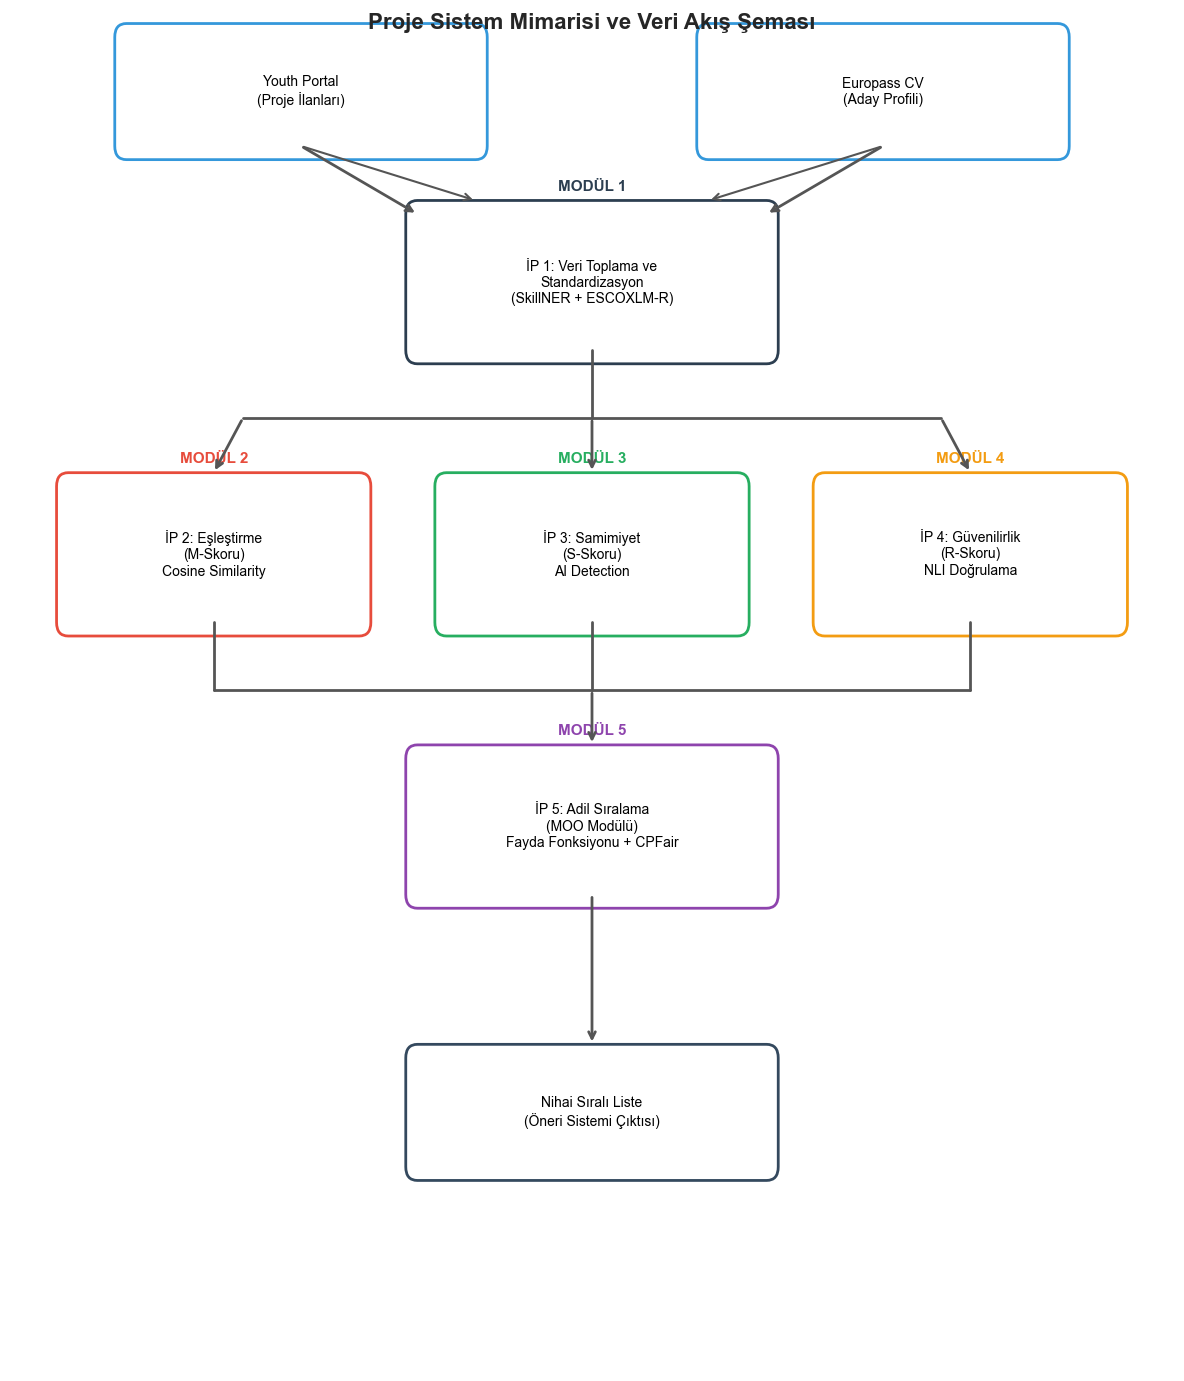


✅ Akış Şeması 'Sistem_Akis_Semasi.png' olarak kaydedildi.


In [3]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def draw_flowchart():
    fig, ax = plt.subplots(figsize=(12, 14))
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 10)
    ax.axis('off') # Eksenleri gizle

    # --- KUTU ÇİZİM FONKSİYONU ---
    def create_box(x, y, width, height, text, color, title=None):
        # Kutu
        rect = patches.FancyBboxPatch((x, y), width, height, 
                                      boxstyle="round,pad=0.1", 
                                      linewidth=2, edgecolor=color, facecolor='white')
        ax.add_patch(rect)
        # İç Metin
        ax.text(x + width/2, y + height/2, text, 
                ha='center', va='center', fontsize=10, color='black')
        # Başlık (Varsa kutunun üstüne)
        if title:
            ax.text(x + width/2, y + height + 0.15, title, 
                    ha='center', va='bottom', fontsize=11, fontweight='bold', color=color)
        return (x + width/2, y) # Alt orta nokta (oklar için)

    # --- OK ÇİZİM FONKSİYONU ---
    def draw_arrow(start_coords, end_coords):
        ax.annotate("", xy=end_coords, xytext=start_coords,
                    arrowprops=dict(arrowstyle="->", lw=2, color="#555555"))

    # --- 1. KATMAN: VERİ KAYNAKLARI (GİRDİLER) ---
    create_box(1, 9, 3, 0.8, "Youth Portal\n(Proje İlanları)", "#3498db")
    create_box(6, 9, 3, 0.8, "Europass CV\n(Aday Profili)", "#3498db")

    # --- 2. KATMAN: İP 1 (VERİ İŞLEME) ---
    ip1_pos = create_box(3.5, 7.5, 3, 1, "İP 1: Veri Toplama ve\nStandardizasyon\n(SkillNER + ESCOXLM-R)", "#2c3e50", "MODÜL 1")
    
    # Oklar (Girdilerden İP 1'e)
    draw_arrow((2.5, 9), (3.5, 8.5)) # Youth Portal -> Sol üst köşe değil, merkeze yakın
    draw_arrow((7.5, 9), (6.5, 8.5)) # CV -> Sağ üst köşe değil, merkeze yakın
    ax.plot([2.5, 2.5, 3.5], [9, 8.5, 8.5], color="#555", lw=0) # Sadece referans
    
    # Manuel ok düzeltmesi
    ax.annotate("", xy=(4, 8.6), xytext=(2.5, 9), arrowprops=dict(arrowstyle="->", lw=1.5, color="#555"))
    ax.annotate("", xy=(6, 8.6), xytext=(7.5, 9), arrowprops=dict(arrowstyle="->", lw=1.5, color="#555"))

    # --- 3. KATMAN: SKORLAMA MODÜLLERİ (PARALEL İŞLEM) ---
    # Ortak Dağıtıcı Nokta
    ax.plot([5, 5], [7.5, 7], color="#555", lw=2) # İP 1'den aşağı inen çizgi
    ax.plot([2, 8], [7, 7], color="#555", lw=2)   # Yatay dağıtıcı çizgi

    # Modüller
    create_box(0.5, 5.5, 2.5, 1, "İP 2: Eşleştirme\n(M-Skoru)\nCosine Similarity", "#e74c3c", "MODÜL 2")
    create_box(3.75, 5.5, 2.5, 1, "İP 3: Samimiyet\n(S-Skoru)\nAI Detection", "#27ae60", "MODÜL 3")
    create_box(7, 5.5, 2.5, 1, "İP 4: Güvenilirlik\n(R-Skoru)\nNLI Doğrulama", "#f39c12", "MODÜL 4")

    # Dağıtıcıdan Modüllere Oklar
    draw_arrow((2, 7), (1.75, 6.6))
    draw_arrow((5, 7), (5, 6.6))
    draw_arrow((8, 7), (8.25, 6.6))

    # --- 4. KATMAN: İP 5 (BİRLEŞTİRME) ---
    # Toplayıcı Nokta
    ax.plot([1.75, 1.75], [5.5, 5], color="#555", lw=2) # İP 2 çıkış
    ax.plot([5, 5], [5.5, 5], color="#555", lw=2)       # İP 3 çıkış
    ax.plot([8.25, 8.25], [5.5, 5], color="#555", lw=2) # İP 4 çıkış
    ax.plot([1.75, 8.25], [5, 5], color="#555", lw=2)   # Yatay toplayıcı

    create_box(3.5, 3.5, 3, 1, "İP 5: Adil Sıralama\n(MOO Modülü)\nFayda Fonksiyonu + CPFair", "#8e44ad", "MODÜL 5")
    draw_arrow((5, 5), (5, 4.6))

    # --- 5. KATMAN: ÇIKTI ---
    create_box(3.5, 1.5, 3, 0.8, "Nihai Sıralı Liste\n(Öneri Sistemi Çıktısı)", "#34495e")
    draw_arrow((5, 3.5), (5, 2.4))

    # Başlık
    plt.title("Proje Sistem Mimarisi ve Veri Akış Şeması", fontsize=16, fontweight='bold', y=0.98)
    
    # Kaydet
    plt.tight_layout()
    plt.savefig("Sistem_Akis_Semasi.png", dpi=300)
    plt.show()

draw_flowchart()
print("\n✅ Akış Şeması 'Sistem_Akis_Semasi.png' olarak kaydedildi.")